In [94]:
from pathlib import Path
from collections import Counter, defaultdict
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import pandas as pd
import re


In [95]:
ROOT = Path("GarbageDataset")
IMG_DIR, LBL_DIR = ROOT / "images", ROOT / "labels"
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
names = ["biodegradable", "cardboard", "glass", "metal", "paper", "plastic"]

In [99]:
images = sorted(p for p in IMG_DIR.rglob("*") if p.suffix.lower() in IMG_EXT)
labels = sorted(LBL_DIR.rglob("*.txt"))

recs = []
for p in images:
    lbl = LBL_DIR / p.relative_to(IMG_DIR).with_suffix(".txt")
    for line in lbl.read_text().splitlines():
        if line.strip():
            c, cx, cy, w, h = line.split()[:5]
            recs.append(dict(img=p.name, cls=int(c), w=float(w), h=float(h), area=float(w) * float(h)))
df = pd.DataFrame(recs)
df["name"] = df.cls.map(dict(enumerate(names)))
print(len(df), "Bboxes |", df.img.nunique(), "images with Bboxes")

74090 Bboxes | 10464 images with Bboxes


Images without label file: 0 | empty label files: 0


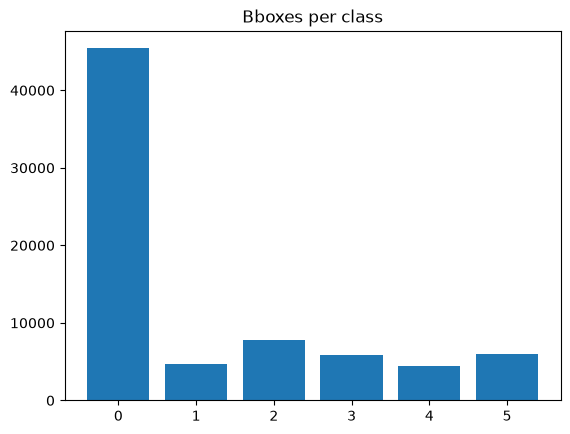

In [100]:
class_counts = Counter()
boxes = defaultdict(list)
missing, empty = [], []

for img_path in images:
    lbl = LBL_DIR / img_path.relative_to(IMG_DIR).with_suffix(".txt")
    if not lbl.exists():
        missing.append(img_path.name)
        continue
    rows = [l.split() for l in lbl.read_text().splitlines() if l.strip()]
    if not rows:
        empty.append(img_path.name)
    for r in rows:
        c = int(r[0])
        class_counts[c] += 1
        boxes[c].append((img_path, *map(float, r[1:5])))

print("Images without label file:", len(missing), "| empty label files:", len(empty))

plt.bar([str(k) for k in sorted(class_counts)], [class_counts[k] for k in sorted(class_counts)])
plt.title("Bboxes per class"); plt.show()

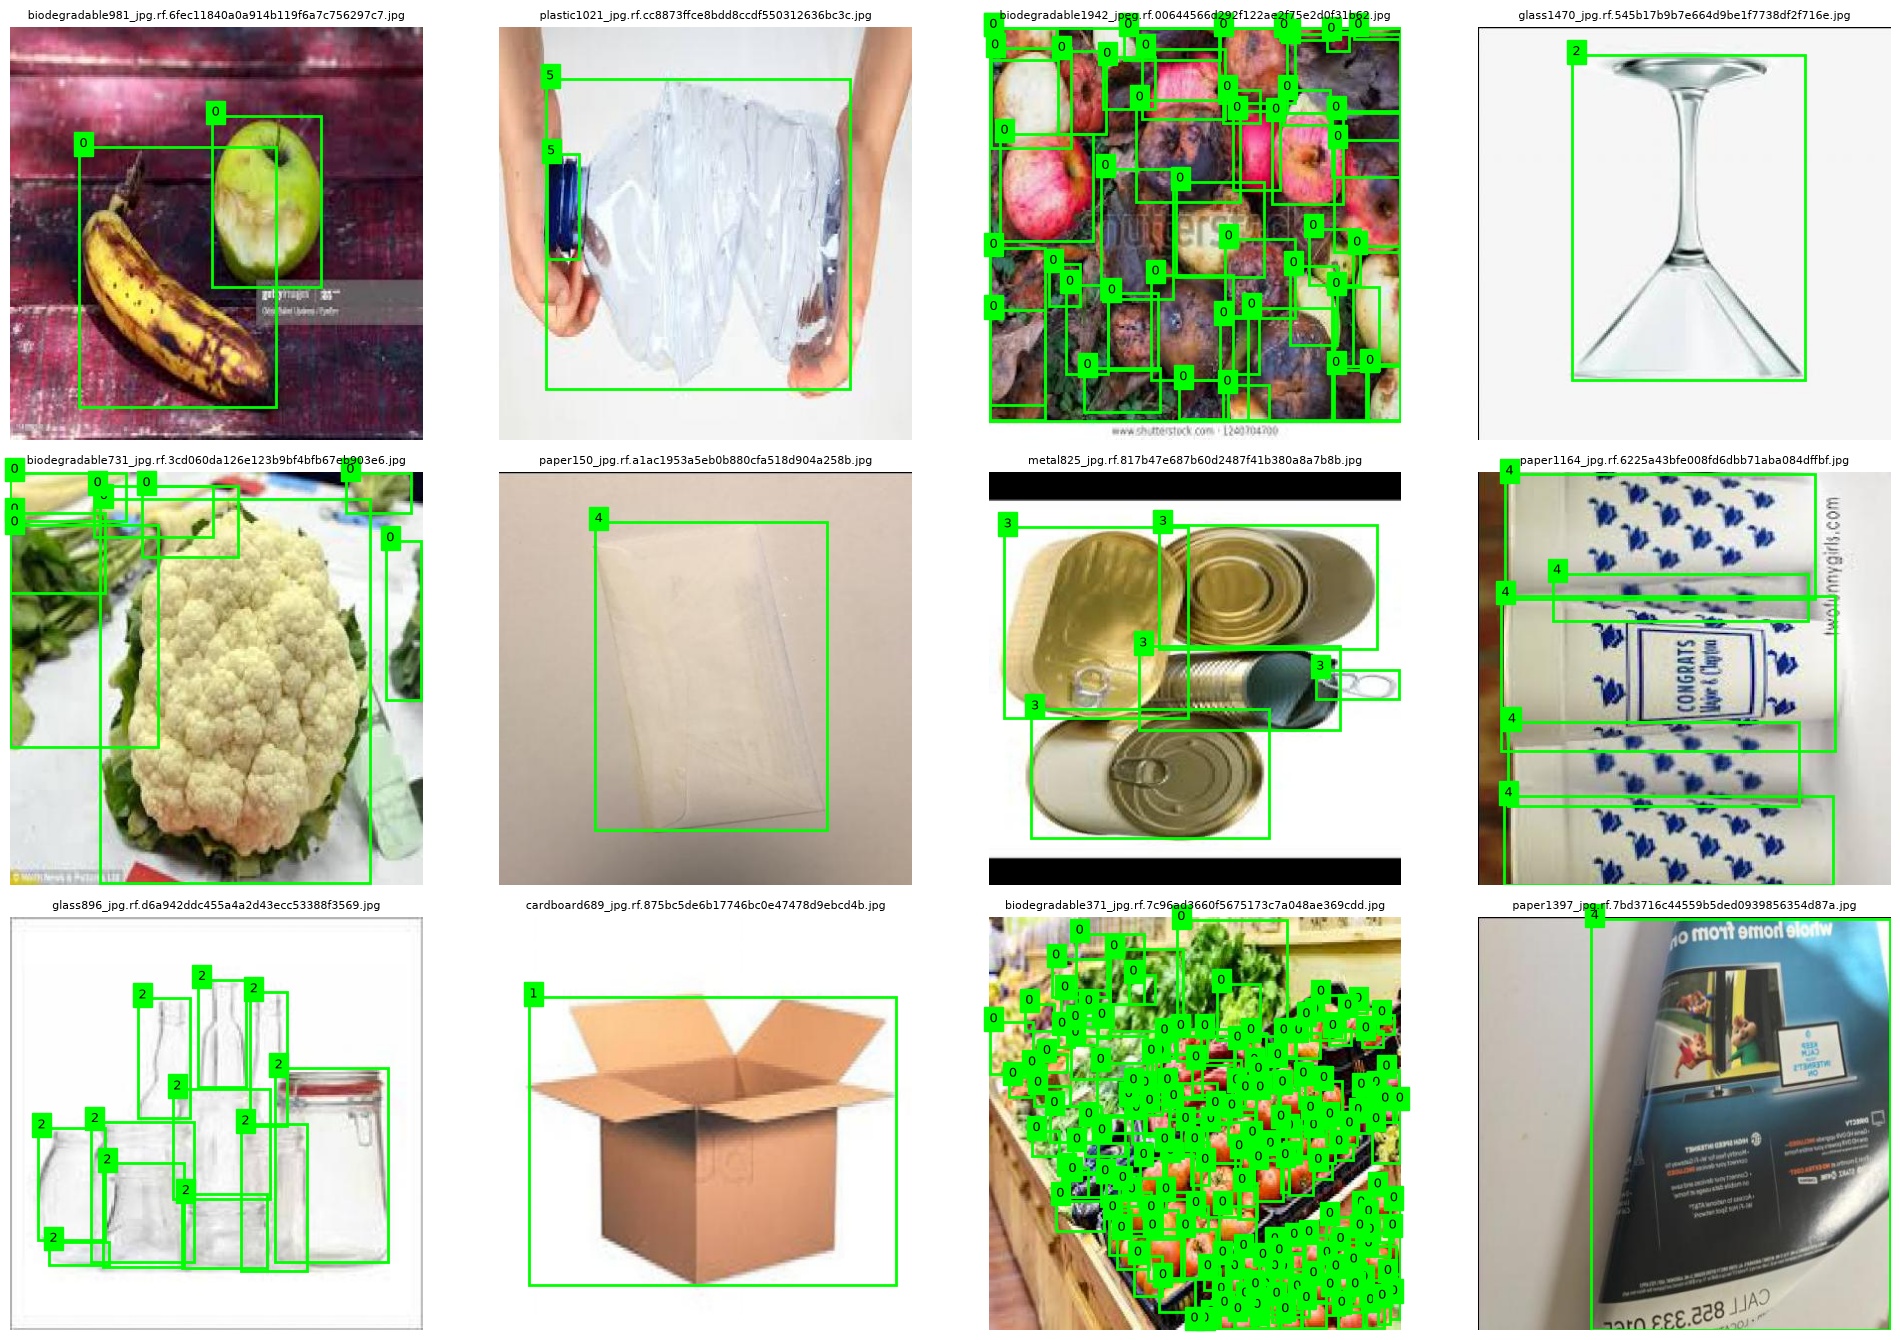

In [101]:
def show_images(n=12, seed=1):
    random.seed(seed)
    sample = random.sample(images, min(n, len(images)))
    cols = 4
    rows_n = (len(sample) + cols - 1) // cols
    fig, axes = plt.subplots(rows_n, cols, figsize=(5 * cols, 4.5 * rows_n))
    for ax, p in zip(axes.flat, sample):
        im = Image.open(p).convert("RGB")
        W, H = im.size
        ax.imshow(im); ax.axis("off"); ax.set_title(p.name, fontsize=8)
        lbl = LBL_DIR / p.relative_to(IMG_DIR).with_suffix(".txt")
        if lbl.exists():
            for line in lbl.read_text().splitlines():
                if not line.strip():
                    continue
                c, cx, cy, w, h = line.split()[:5]
                cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
                ax.add_patch(patches.Rectangle((cx - w / 2, cy - h / 2), w, h, fill=False, color="lime", lw=2))
                ax.text(cx - w / 2, cy - h / 2, c, color="black", fontsize=9, backgroundcolor="lime")
    for ax in list(axes.flat)[len(sample):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()

show_images()

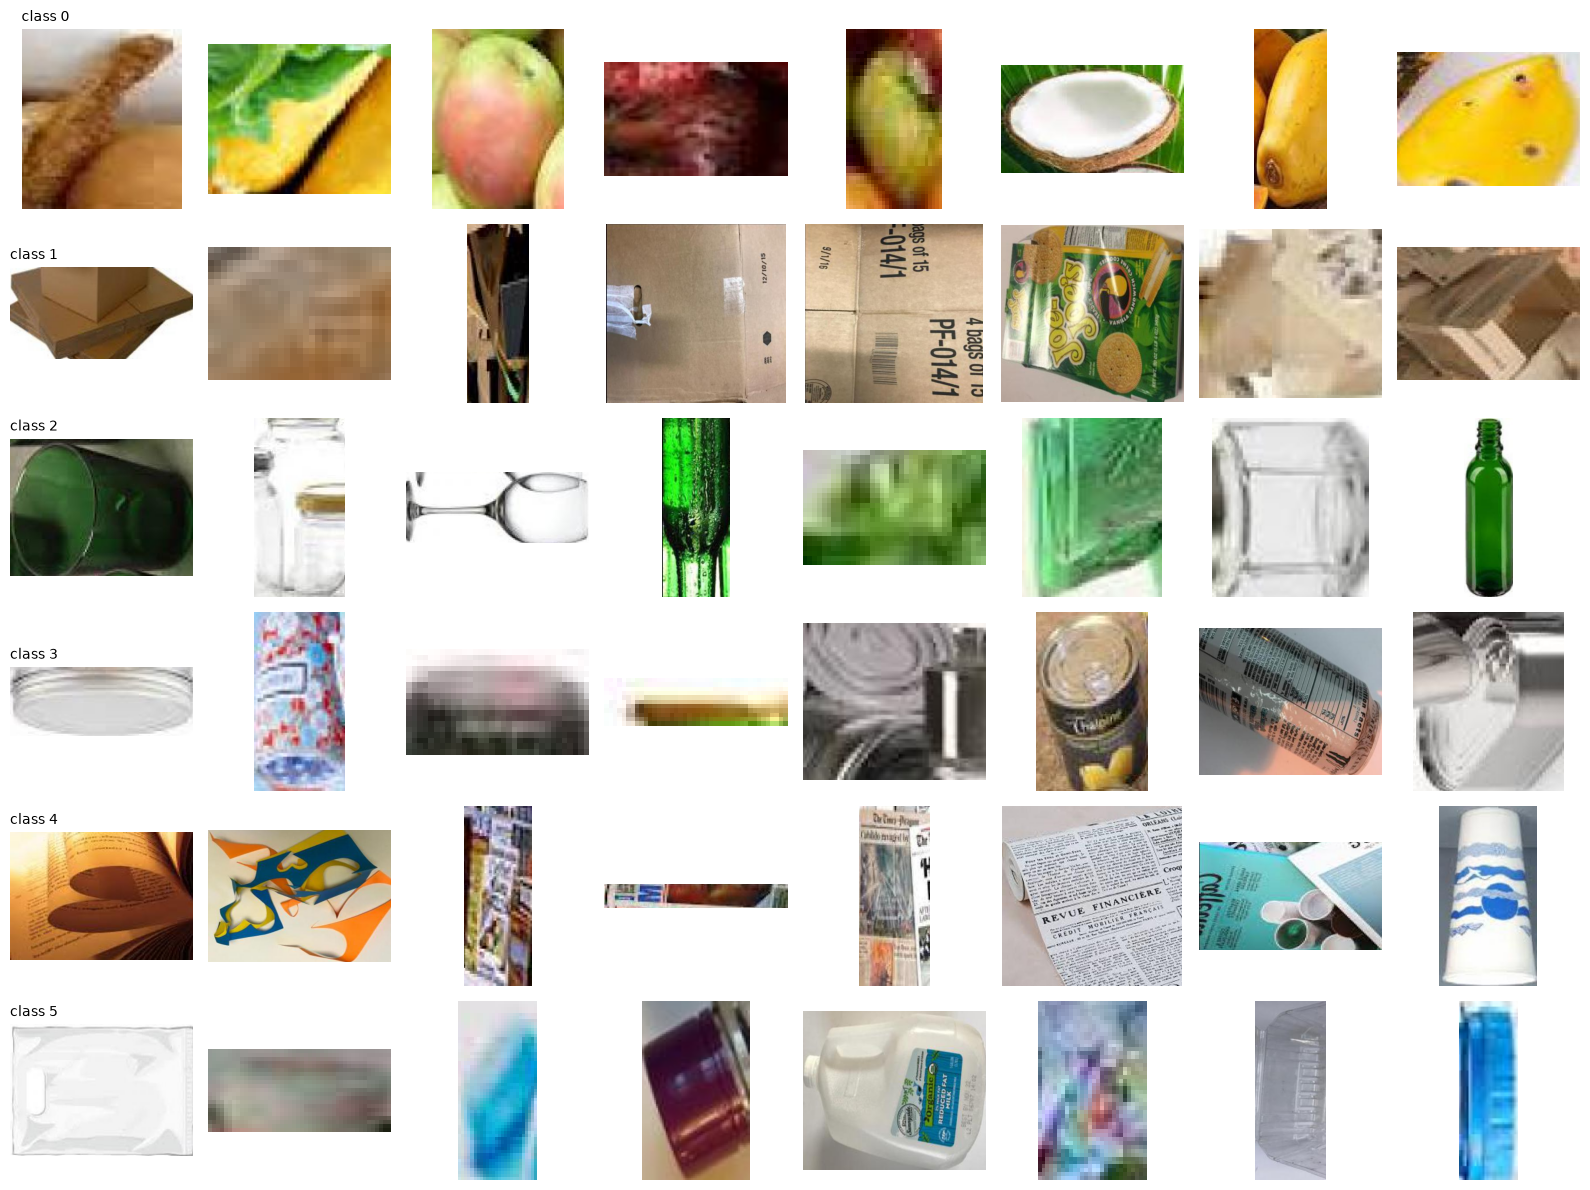

In [63]:
def show_class_crops(n=8, seed=0):
    random.seed(seed)
    ids = sorted(boxes)
    fig, axes = plt.subplots(len(ids), n, figsize=(2 * n, 2 * len(ids)))
    axes = np.atleast_2d(axes)
    for r, c in enumerate(ids):
        sample = random.sample(boxes[c], min(n, len(boxes[c])))
        for k in range(n):
            ax = axes[r, k]; ax.axis("off")
            if k < len(sample):
                p, cx, cy, w, h = sample[k]
                im = Image.open(p).convert("RGB"); W, H = im.size
                ax.imshow(im.crop((int((cx - w / 2) * W), int((cy - h / 2) * H), int((cx + w / 2) * W), int((cy + h / 2) * H))))
            if k == 0:
                ax.set_title(f"class {c}", fontsize=10, loc="left")
    plt.tight_layout(); plt.show()

show_class_crops()

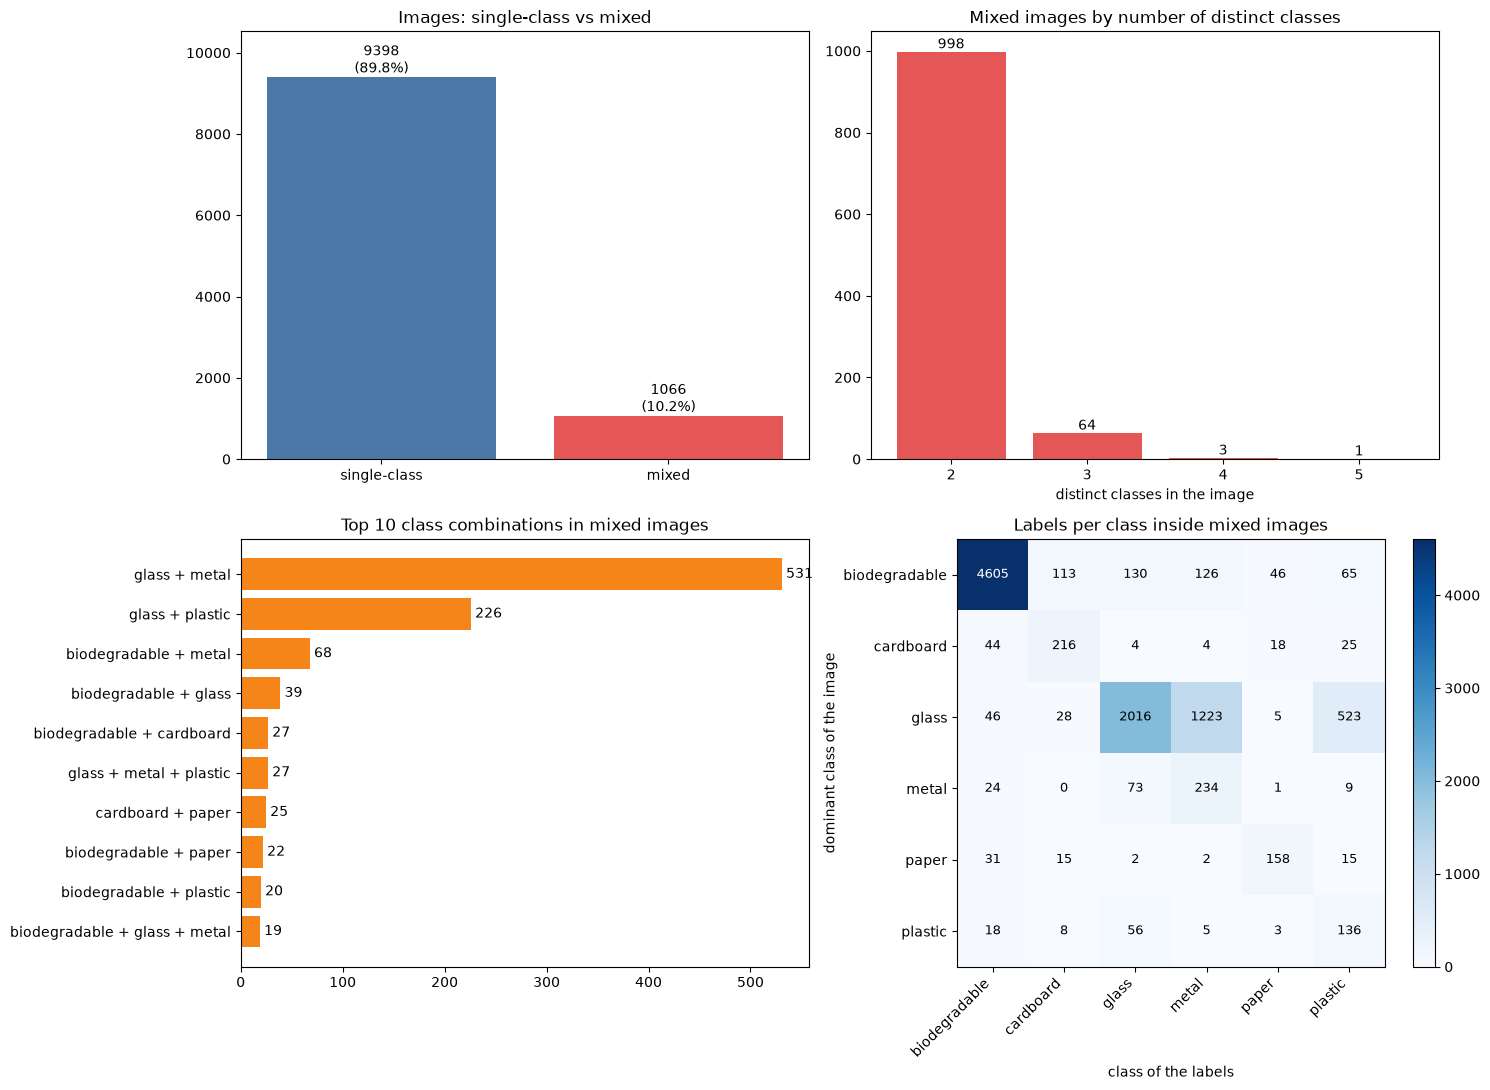

In [102]:
from collections import Counter

# per-image box count for each class: one row per image, one column per class
rows = []
for p in images:
    lbl = LBL_DIR / p.relative_to(IMG_DIR).with_suffix(".txt")
    counts = np.zeros(len(names), dtype=int)
    for line in lbl.read_text().splitlines():
        if line.strip():
            counts[int(line.split()[0])] += 1
    rows.append(counts)
M = pd.DataFrame(rows, columns=names, index=[p.name for p in images])

M["n_classes"] = (M[names] > 0).sum(axis=1)
M["dominant"] = M[names].idxmax(axis=1)
mixed = M[M.n_classes > 1]
single = M[M.n_classes == 1]



# class combinations in mixed images
combo = mixed[names].gt(0).apply(lambda r: " + ".join(n for n in names if r[n]), axis=1)
combo_counts = combo.value_counts()


# rows = dominant class of the image, columns = labels of each class in those images
heat = mixed.groupby("dominant")[names].sum().reindex(names).fillna(0).astype(int)


# plots
fig, ax = plt.subplots(2, 2, figsize=(15, 11))

ax[0, 0].bar(["single-class", "mixed"], [len(single), len(mixed)], color=["#4C78A8", "#E45756"])
for i, v in enumerate([len(single), len(mixed)]):
    ax[0, 0].text(i, v, f"{v}\n({v/len(M):.1%})", ha="center", va="bottom")
ax[0, 0].set_title("Images: single-class vs mixed")
ax[0, 0].set_ylim(0, len(single) * 1.12)

nc = mixed.n_classes.value_counts().sort_index()
ax[0, 1].bar(nc.index.astype(str), nc.values, color="#E45756")
for i, v in enumerate(nc.values):
    ax[0, 1].text(i, v, str(v), ha="center", va="bottom")
ax[0, 1].set_title("Mixed images by number of distinct classes")
ax[0, 1].set_xlabel("distinct classes in the image")

top = combo_counts.head(10)[::-1]
ax[1, 0].barh(top.index, top.values, color="#F58518")
for i, v in enumerate(top.values):
    ax[1, 0].text(v, i, f" {v}", va="center")
ax[1, 0].set_title("Top 10 class combinations in mixed images")

im = ax[1, 1].imshow(heat.values, cmap="Blues")
ax[1, 1].set_xticks(range(len(names))); ax[1, 1].set_xticklabels(names, rotation=45, ha="right")
ax[1, 1].set_yticks(range(len(names))); ax[1, 1].set_yticklabels(names)
ax[1, 1].set_xlabel("class of the labels"); ax[1, 1].set_ylabel("dominant class of the image")
ax[1, 1].set_title("Labels per class inside mixed images")
vmax = heat.values.max()
for i in range(len(names)):
    for j in range(len(names)):
        v = heat.values[i, j]
        ax[1, 1].text(j, i, v, ha="center", va="center", color="white" if v > vmax * 0.5 else "black", fontsize=9)
plt.colorbar(im, ax=ax[1, 1], fraction=0.046)

plt.tight_layout()
plt.savefig("mixed_class_analysis.png", dpi=150)
plt.show()

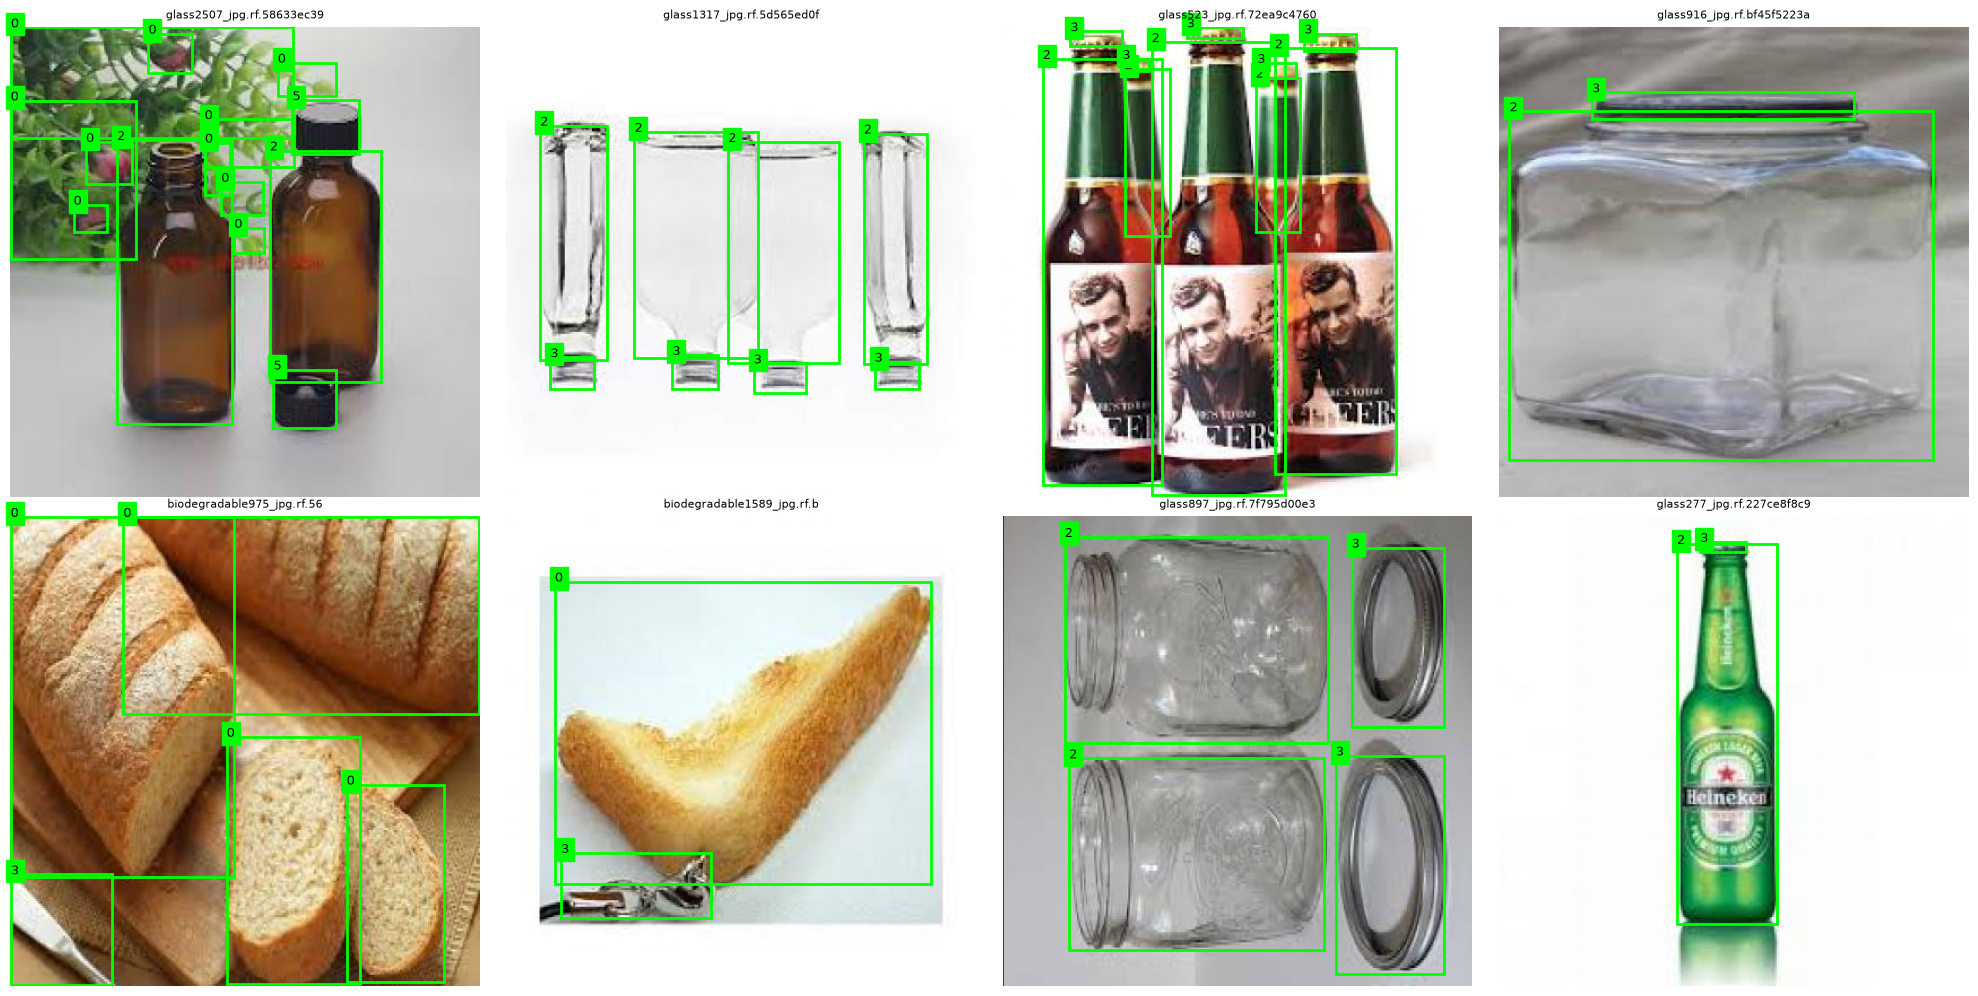

In [103]:
def classes_in(p):
    lbl = LBL_DIR / p.relative_to(IMG_DIR).with_suffix(".txt")
    return sorted({int(l.split()[0]) for l in lbl.read_text().splitlines() if l.strip()})

multi = [p for p in images if len(classes_in(p)) > 1]

multi_df = pd.DataFrame({"img": [p.name for p in multi]})
multi_df["prefix"] = multi_df.img.str.extract(r"^([A-Za-z]+)")[0].str.lower()

mixed_boxes = df[df.img.isin(set(multi_df.img))]

random.seed(3)
sample = random.sample(multi, 8)
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, p in zip(axes.flat, sample):
    im = Image.open(p).convert("RGB"); W, H = im.size
    ax.imshow(im); ax.axis("off"); ax.set_title(p.name[:26], fontsize=8)
    for line in (LBL_DIR / p.relative_to(IMG_DIR).with_suffix(".txt")).read_text().splitlines():
        if line.strip():
            c, cx, cy, w, h = line.split()[:5]
            cx, cy, w, h = float(cx)*W, float(cy)*H, float(w)*W, float(h)*H
            ax.add_patch(patches.Rectangle((cx-w/2, cy-h/2), w, h, fill=False, color="lime", lw=2))
            ax.text(cx-w/2, cy-h/2, c, backgroundcolor="lime", fontsize=9)
plt.tight_layout(); plt.show()

In [104]:

rows = []
for p in images:
    lbl = LBL_DIR / p.relative_to(IMG_DIR).with_suffix(".txt")
    counts = [0] * len(names)
    for line in lbl.read_text().splitlines():
        if line.strip():
            counts[int(line.split()[0])] += 1
    rows.append(dict(img=p.name, **dict(zip(names, counts))))

df = pd.DataFrame(rows).set_index("img")
df["n_boxes"] = df[names].sum(axis=1)
df["n_classes"] = (df[names] > 0).sum(axis=1)
df["mixed"] = df.n_classes > 1
df["dominant"] = df[names].idxmax(axis=1)

print(df.shape)
print("Total boxes:", df.n_boxes.sum())
print("Images:", len(df), "| mixed:", df.mixed.sum(), "| single-class:", (~df.mixed).sum())
print(df[names].sum().to_string())
df.head()

(10464, 10)
Total boxes: 74090
Images: 10464 | mixed: 1066 | single-class: 9398
biodegradable    45407
cardboard         4698
glass             7809
metal             5841
paper             4390
plastic           5945


,biodegradable,cardboard,glass,metal,paper,plastic,n_boxes,n_classes,mixed,dominant
img,,,,,,,,,,
biodegradable1000_jpg.rf.9407ff66b4ccd9f8eb5545be8f3225f4.jpg,21,0,0,0,0,0,21,1,False,biodegradable
biodegradable1001_jpg.rf.7903fa84ae12e27e6ee0149bdeeb1876.jpg,45,0,0,0,0,0,45,1,False,biodegradable
biodegradable1002_jpg.rf.b9ead478ce5c0cfe58bc8e0829251a5d.jpg,3,0,0,0,0,0,3,1,False,biodegradable
biodegradable1003_jpg.rf.f77cec0a34271415dceadf61af516ca8.jpg,3,0,0,0,0,0,3,1,False,biodegradable
biodegradable1004_jpg.rf.645d319975e53c260b201677f2f39981.jpg,46,0,0,0,0,0,46,1,False,biodegradable


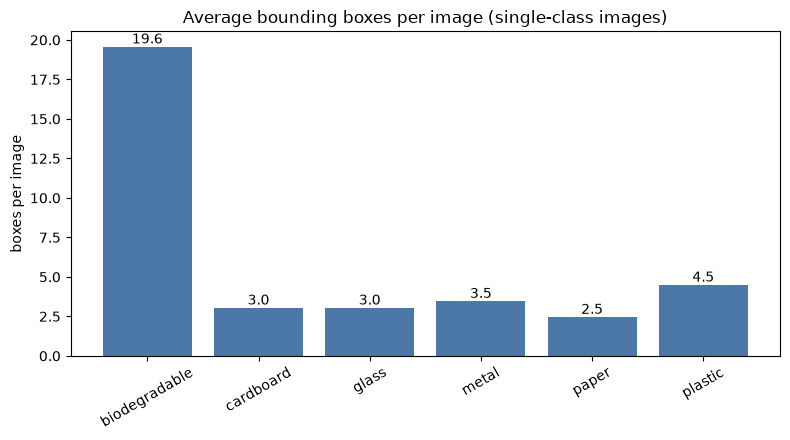

In [105]:
single = df[~df.mixed]
avg = single.groupby("dominant").n_boxes.mean().reindex(names)

plt.figure(figsize=(8, 4.5))
plt.bar(names, avg.values, color="#4C78A8")
for i, v in enumerate(avg.values):
    plt.text(i, v, f"{v:.1f}", ha="center", va="bottom")
plt.title("Average bounding boxes per image (single-class images)")
plt.ylabel("boxes per image")
plt.xticks(rotation=30)
plt.tight_layout(); plt.show()

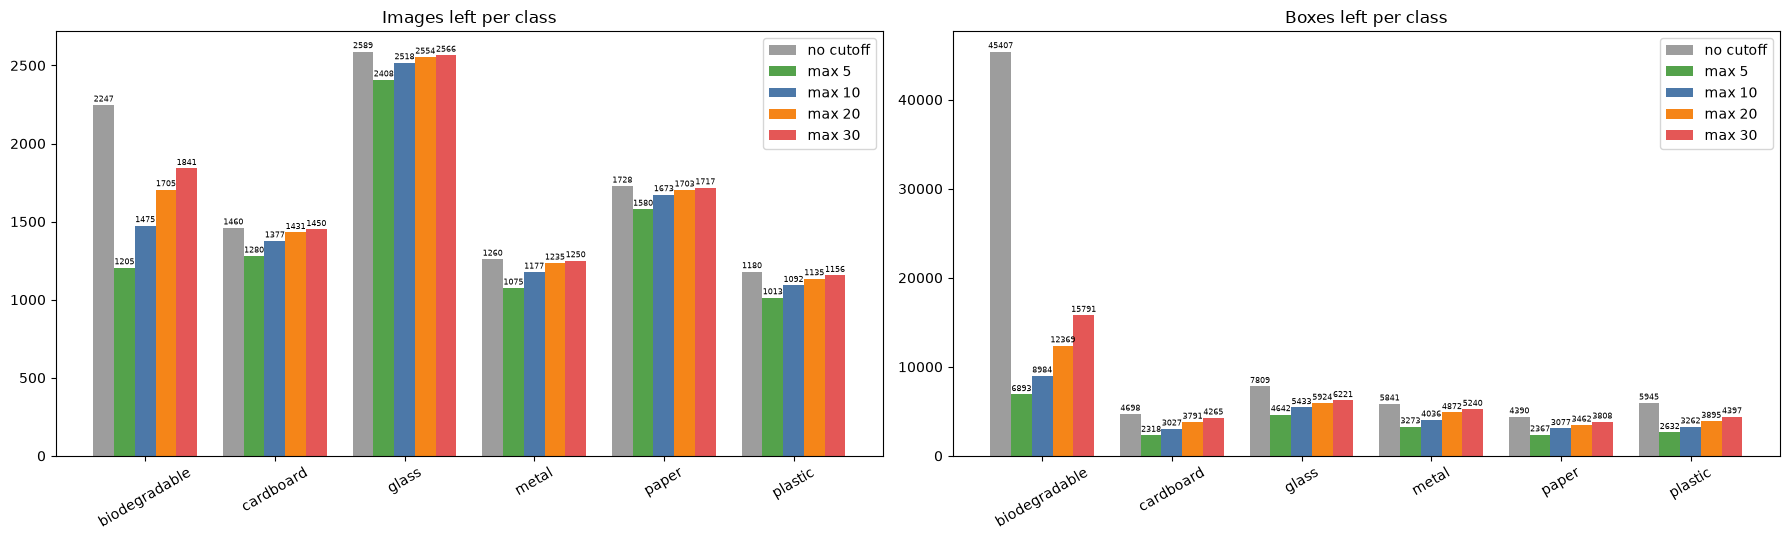

In [106]:
cutoffs = [None, 5, 10, 20, 30]
labels = ["no cutoff", "max 5", "max 10", "max 20", "max 30"]

imgs_left, boxes_left = {}, {}
for c, lab in zip(cutoffs, labels):
    keep = df if c is None else df[~((~df.mixed) & (df.n_boxes > c))]
    imgs_left[lab] = keep.groupby("dominant").size().reindex(names).fillna(0)
    boxes_left[lab] = keep[names].sum()

x = np.arange(len(names)); w = 0.16
colors = ["#9D9D9D", "#54A24B", "#4C78A8", "#F58518", "#E45756"]

fig, ax = plt.subplots(1, 2, figsize=(18, 5.5))
for k, (lab, col) in enumerate(zip(labels, colors)):
    for a, data in zip(ax, (imgs_left, boxes_left)):
        bars = a.bar(x + (k - 2) * w, data[lab].values, w, label=lab, color=col)
        a.bar_label(bars, fmt="%d", fontsize=6, padding=1)
for a, title in zip(ax, ("Images left per class", "Boxes left per class")):
    a.set_xticks(x); a.set_xticklabels(names, rotation=30)
    a.set_title(title)
    a.legend()
plt.tight_layout(); plt.show()

In [107]:
# backup of the full data, created once
if "df_before" not in globals():
    assert len(df) == 10464, "df is not the full table: rerun step 1 (build df) first"
    df_before, images_before = df.copy(), list(images)

df, images = df_before.copy(), list(images_before)   # every run starts from the full set

BIO = "biodegradable"
CUT = 5                # drop single-class bio images with >= 5 boxes
KEEP_FROM = 15         # ...except a few of those with >= 15 boxes
KEEP_N = 50            # how many of the >= 15 images to leave in
KEEP_MAX_BOXES = 60    # the kept ones can't have more boxes than this
SEED = 42

bio_single = df[(~df.mixed) & (df.dominant == BIO)]
dense = bio_single[bio_single.n_boxes >= CUT]
pool = dense[(dense.n_boxes >= KEEP_FROM) & (dense.n_boxes <= KEEP_MAX_BOXES)]

rng = np.random.default_rng(SEED)
leave = rng.choice(pool.index.to_numpy(), size=min(KEEP_N, len(pool)), replace=False)
drop = dense.index.difference(leave)

df = df.drop(drop)
images = [p for p in images_before if p.name in df.index]

print(f"Bio single-class images with >= {CUT} boxes: {len(dense)}")
print(f"  eligible to stay ({KEEP_FROM}-{KEEP_MAX_BOXES} boxes): {len(pool)} | left in: {len(leave)} | dropped in total: {len(drop)}")
print(f"\nLeft: {len(images)} images, {df.n_boxes.sum()} boxes")
print(pd.DataFrame({"images": df.groupby("dominant").size().reindex(names),
                    "boxes": df[names].sum()}).to_string())

bio_left = df[(~df.mixed) & (df.dominant == BIO)].n_boxes
print("\nBio single-class images left, by boxes per image:")
print(pd.cut(bio_left, [0, 4, 14, 60, 1000], labels=["1-4", "5-14", "15-60", ">60"]).value_counts().sort_index().to_string())

Bio single-class images with >= 5 boxes: 1109
  eligible to stay (15-60 boxes): 474 | left in: 50 | dropped in total: 1059

Left: 9405 images, 36879 boxes
               images  boxes
biodegradable    1188   8196
cardboard        1460   4698
glass            2589   7809
metal            1260   5841
paper            1728   4390
plastic          1180   5945

Bio single-class images left, by boxes per image:
n_boxes
1-4      968
5-14       0
15-60     50
>60        0


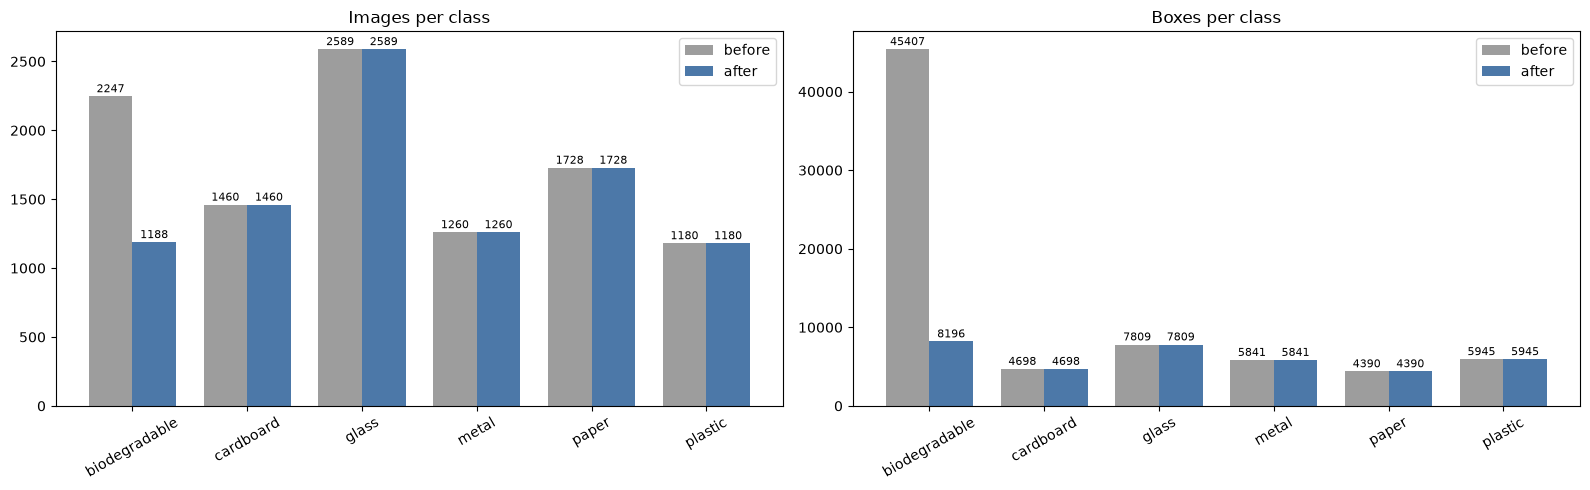

In [108]:
x = np.arange(len(names)); w = 0.38
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

for a, (before, after, title) in zip(ax, [
    (df_before.groupby("dominant").size().reindex(names), df.groupby("dominant").size().reindex(names), "Images per class"),
    (df_before[names].sum(), df[names].sum(), "Boxes per class"),
]):
    b1 = a.bar(x - w/2, before.values, w, label="before", color="#9D9D9D")
    b2 = a.bar(x + w/2, after.values, w, label="after", color="#4C78A8")
    a.bar_label(b1, fmt="%d", fontsize=8, padding=1)
    a.bar_label(b2, fmt="%d", fontsize=8, padding=1)
    a.set_xticks(x); a.set_xticklabels(names, rotation=30)
    a.set_title(title); a.legend()
plt.tight_layout(); plt.show()

# Data Split

In [109]:
import shutil
from sklearn.model_selection import StratifiedGroupKFold

# 1. near-duplicate groups on the cleaned images (256-bit difference hash, max 10 differing bits)
def dhash16(path):
    im = Image.open(path).convert("L").resize((17, 16), Image.LANCZOS)
    a = np.asarray(im, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).flatten())

H = np.stack([dhash16(p) for p in images])
bitcount = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
parent = list(range(len(images)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

for s in range(0, len(H), 256):
    d = bitcount[H[s:s+256, None, :] ^ H[None, :, :]].sum(-1)
    for a, b in zip(*np.where(d <= 10)):
        a += s
        if a < b:
            parent[find(a)] = find(b)

group = [find(i) for i in range(len(images))]
sz = Counter(group)
print("Duplicate groups:", len(sz), "| images in groups of size >1:", sum(v for v in sz.values() if v > 1))

# 2. stratification label: dominant class + mixed/single flag, rare strata merged
strat = (df.loc[[p.name for p in images], "dominant"] + np.where(df.loc[[p.name for p in images], "mixed"], "_mixed", "_single")).values
vc = pd.Series(strat).value_counts()
strat = np.where(pd.Series(strat).map(vc) < 30, "rare", strat)

# 3. grouped, stratified split (about 71 / 14 / 14)
OUT = Path("GarbageSplit")
if OUT.exists():
    shutil.rmtree(OUT)

X = np.arange(len(images))
folds = list(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42).split(X, strat, group))
test_idx, val_idx = folds[0][1], folds[1][1]
train_idx = np.setdiff1d(X, np.concatenate([test_idx, val_idx]))
split = {"train": train_idx, "val": val_idx, "test": test_idx}

for name, idx in split.items():
    (OUT / "images" / name).mkdir(parents=True, exist_ok=True)
    (OUT / "labels" / name).mkdir(parents=True, exist_ok=True)
    for i in idx:
        p = images[i]
        shutil.copy(p, OUT / "images" / name / p.name)
        shutil.copy(LBL_DIR / p.relative_to(IMG_DIR).with_suffix(".txt"),
                    OUT / "labels" / name / (p.stem + ".txt"))

# 4. checks and report
for a in split:
    for b in split:
        if a < b:
            assert not ({group[i] for i in split[a]} & {group[i] for i in split[b]}), f"leak {a}/{b}"
print("No duplicate group spans two splits.\n")

rows = []
for name, idx in split.items():
    sub = df.loc[[images[i].name for i in idx]]
    rows.append({"split": name, "images": len(sub), "mixed_imgs": int(sub.mixed.sum()), **{n[:5] + "_boxes": int(sub[n].sum()) for n in names}})
rep = pd.DataFrame(rows).set_index("split")
print(rep.to_string())
print("\nShare of each class's boxes per split (%):")
print((rep.filter(like="_boxes") / rep.filter(like="_boxes").sum() * 100).round(1).to_string())



Duplicate groups: 9379 | images in groups of size >1: 44
No duplicate group spans two splits.

       images  mixed_imgs  biode_boxes  cardb_boxes  glass_boxes  metal_boxes  paper_boxes  plast_boxes
split                                                                                                  
train    6717         762         5495         3271         5733         4222         2882         4118
val      1344         151         1498          660         1146          756          571          957
test     1344         153         1203          767          930          863          937          870

Share of each class's boxes per split (%):
       biode_boxes  cardb_boxes  glass_boxes  metal_boxes  paper_boxes  plast_boxes
split                                                                              
train         67.0         69.6         73.4         72.3         65.6         69.3
val           18.3         14.0         14.7         12.9         13.0         16.1
test 

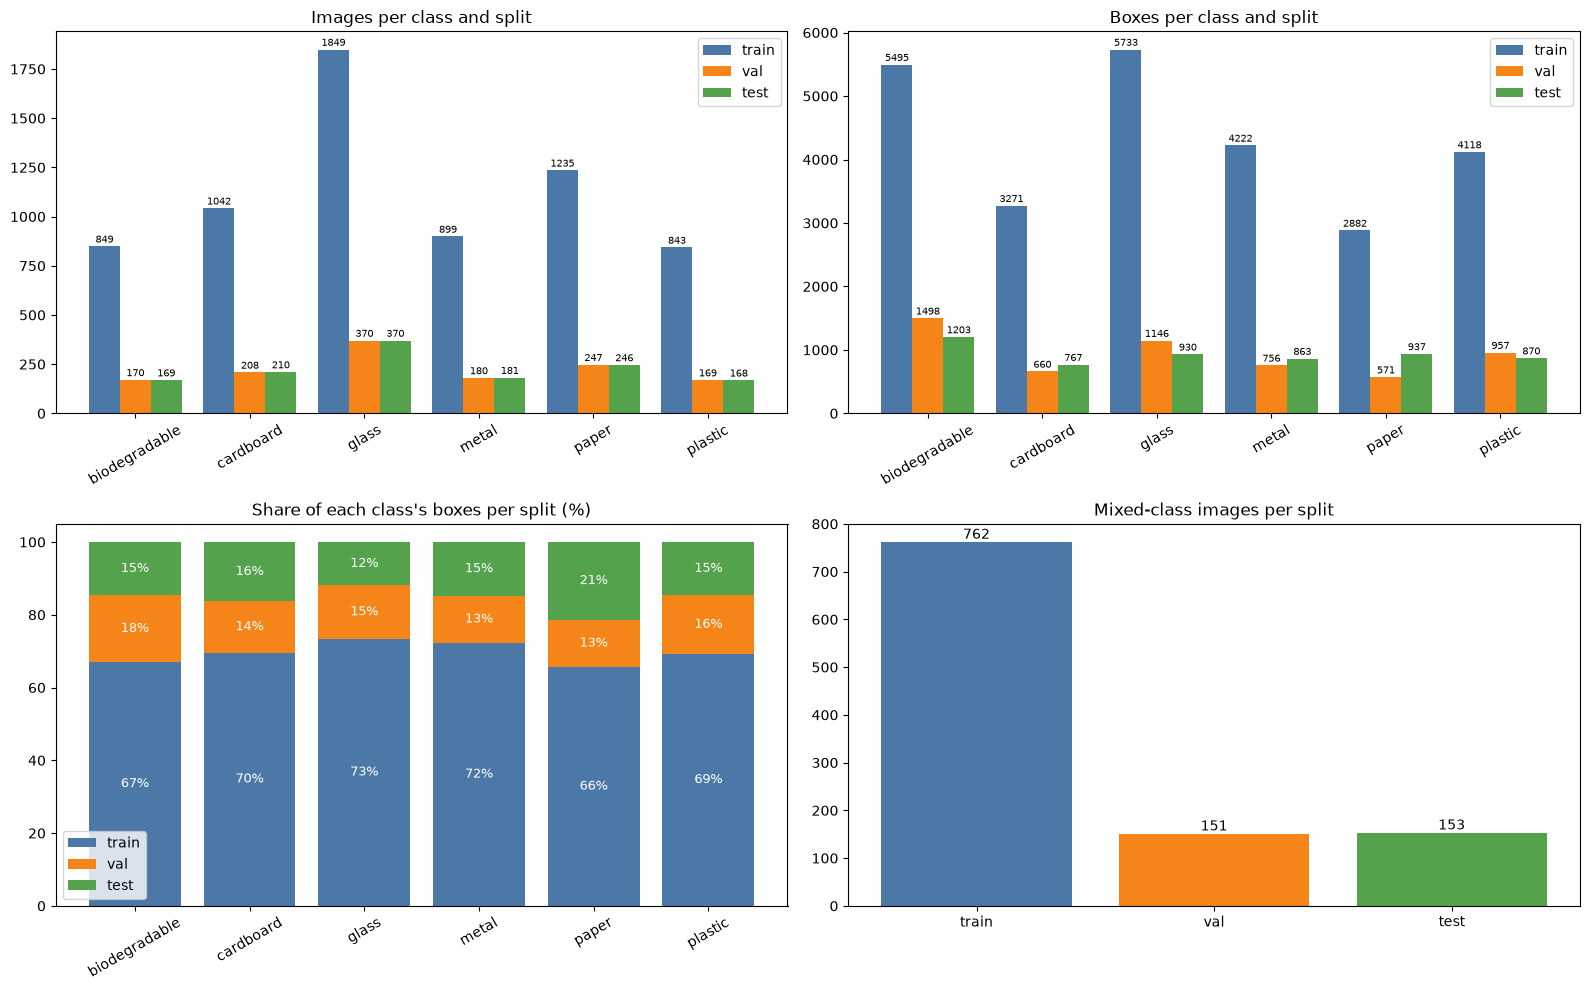

In [110]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

OUT = Path("GarbageSplit")
sets = ["train", "val", "test"]
colors = {"train": "#4C78A8", "val": "#F58518", "test": "#54A24B"}

split_df = {s: df.loc[[p.name for p in sorted((OUT / "images" / s).iterdir())]] for s in sets}

imgs = pd.DataFrame({s: split_df[s].groupby("dominant").size().reindex(names).fillna(0) for s in sets})
boxes = pd.DataFrame({s: split_df[s][names].sum() for s in sets})
mixed = pd.Series({s: int(split_df[s].mixed.sum()) for s in sets})

x = np.arange(len(names)); w = 0.27
fig, ax = plt.subplots(2, 2, figsize=(16, 10))

for a, data, title in [(ax[0, 0], imgs, "Images per class and split"), (ax[0, 1], boxes, "Boxes per class and split")]:
    for k, s in enumerate(sets):
        bars = a.bar(x + (k - 1) * w, data[s].values, w, label=s, color=colors[s])
        a.bar_label(bars, fmt="%d", fontsize=7, padding=1)
    a.set_xticks(x); a.set_xticklabels(names, rotation=30)
    a.set_title(title); a.legend()

# share of each class's boxes that falls into each split
share = boxes.div(boxes.sum(axis=1), axis=0) * 100
bottom = np.zeros(len(names))
for s in sets:
    ax[1, 0].bar(names, share[s].values, bottom=bottom, label=s, color=colors[s])
    for i, v in enumerate(share[s].values):
        ax[1, 0].text(i, bottom[i] + v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    bottom += share[s].values
ax[1, 0].set_title("Share of each class's boxes per split (%)")
ax[1, 0].tick_params(axis="x", rotation=30); ax[1, 0].legend()

bars = ax[1, 1].bar(sets, mixed.values, color=[colors[s] for s in sets])
ax[1, 1].bar_label(bars, fmt="%d")
ax[1, 1].set_title("Mixed-class images per split")

plt.tight_layout()
plt.savefig("split_distribution.png", dpi=150)
plt.show()